# Лабораторна № 3
**Тема:** Навчання з підкріпленням (Reinforcement Learning). Реалізація алгоритму Q-learning у середовищі Gymnasium.   
**Мета:** Засвоїти основні відомості про навчання з підкріпленням та навчитися використовувати його на практиці.


- **Середовище (environment)** - це гра. Її дає готова бібліотека Gymnasium.  
- **Агент** - наша програма. На кожному кроці вона дивиться на стан гри і вибирає дію.  
- За кожну дію гра дає винагороду (**reward**). Агент хоче набрати якомога більше винагороди.  
- Вчиться агент алгоритмом **Q-learning**. Він заповнює Q-таблицю: для кожного стану записує, наскільки вигідна кожна дія. Коли таблиця навчена, агент у кожному стані просто бере дію з найбільшим числом.

Формула оновлення таблиці:

Q(s,a) = (1 − α)·Q(s,a) + α·(r + γ·max Q(s', a'))

**α (learning rate)** - наскільки сильно нова інформація змінює старе значення, наприклад 0.1.  
**γ (gamma)** - наскільки агент цінує майбутні нагороди, а не лише нагороду зараз, наприклад 0.99.  
**ε-greedy:** з ймовірністю ε агент робить випадкову дію (пробує нове), а в решті випадків бере найкращу відому. Спочатку ε велике (≈1), потім поступово зменшується.

### Варіант - 7: Acrobot

Це два стрижні, з'єднані шарніром, ніби рука з ліктем. Верхній кінець закріплений, і все це висить донизу. Мотор є тільки в «лікті».

**Мета:** розгойдати систему так, щоб кінчик нижнього стрижня піднявся вище за лінію над точкою кріплення.  
**Дії** (Discrete(3)): 0 - крутити ліворуч, 1 - нічого не робити, 2 - крутити праворуч.  
**Стан** (Box(6)): 6 чисел з комою: cos θ1, sin θ1, cos θ2, sin θ2 і дві кутові швидкості.  
**Винагорода:** −1 за кожен крок, поки мети не досягнуто. Тому агент вчиться дійти до мети якомога швидше.  

Епізод закінчується, коли мети досягнуто або минуло 500 кроків. Отже, найгірший результат −500. Добрим результатом вважається приблизно -100 і вище.

**Головна складність: дискретизація**

Q-таблиця працює тільки з обмеженою кількістю станів. А в Acrobot стан складається з 6 чисел з комою, тобто можливих станів нескінченно багато. Тому кожне число розбивають на «кошики» (bins). Наприклад, cos θ1 від −1 до 1 ділять на 6-10 проміжків, і кожне значення замінюють номером його проміжку. Тоді стан стає набором з 6 цілих номерів, і з ним уже можна працювати як з адресою рядка Q-таблиці.

## Завдання 1-2. Ознайомлення з Gymnasium та середовищем Acrobot

У цьому завданні ми встановлюємо бібліотеку, створюємо середовище `Acrobot-v1` і дивимось:
- які **дії** може робити агент (простір дій);
- як виглядає **стан** (простір спостережень) і в яких межах він змінюється;
- що відбувається, якщо агент просто робить **випадкові дії**.

In [2]:
%pip install "gymnasium[classic-control]" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import gymnasium as gym
import numpy as np

env = gym.make("Acrobot-v1")

print("Простір дій:", env.action_space)
print("Простір станів:", env.observation_space)
print("Нижні межі станів:", env.observation_space.low)
print("Верхні межі станів:", env.observation_space.high)

Простір дій: Discrete(3)
Простір станів: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Нижні межі станів: [ -1.        -1.        -1.        -1.       -12.566371 -28.274334]
Верхні межі станів: [ 1.        1.        1.        1.       12.566371 28.274334]


**Що ми бачимо:**
- `Discrete(3)` - агент має 3 дії: `0` (крутити ліворуч), `1` (нічого не робити), `2` (крутити праворуч).
- `Box(6)` - стан складається з 6 неперервних чисел: `cos θ1, sin θ1, cos θ2, sin θ2` (від -1 до 1) і дві кутові швидкості (приблизно ±12.57 та ±28.27).

| № | Що це |
|---|---|
| 0 | `cos θ1` - кут верхнього стрижня |
| 1 | `sin θ1` |
| 2 | `cos θ2` - кут нижнього стрижня відносно верхнього |
| 3 | `sin θ2` |
| 4 | Швидкість обертання верхнього стрижня |
| 5 | Швидкість обертання нижнього стрижня |

Оскільки стан неперервний, для Q-таблиці його потрібно буде **дискретизувати** (розбити на «кошики»).

In [4]:
# Один епізод з випадковими діями
obs, info = env.reset(seed=42)
print("Початковий стан:", obs)

total_reward = 0
steps = 0
while True:
    action = env.action_space.sample() # випадкова дія
    obs, reward, terminated, truncated, info = env.step(action) # крок у середовищі
    total_reward += reward
    steps += 1
    if terminated or truncated: # кінець епізоду
        break

print(f"Кроків: {steps}, сумарна винагорода: {total_reward}")
print(f"terminated = {terminated} (чи досягнуто мети), truncated = {truncated} (чи вийшов ліміт 500 кроків)")

Початковий стан: [ 0.99849933  0.0547638   0.99992526 -0.01222401  0.07171959  0.0394736 ]
Кроків: 500, сумарна винагорода: -500.0
terminated = False (чи досягнуто мети), truncated = True (чи вийшов ліміт 500 кроків)


In [5]:
# Середній результат випадкового агента за 20 епізодів
random_rewards = []
for ep in range(20):
    obs, info = env.reset()
    ep_reward = 0
    done = False
    while not done:
        obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
        ep_reward += reward
        done = terminated or truncated
    random_rewards.append(ep_reward)

env.close()
print("Винагороди:", random_rewards)
print("Середня винагорода випадкового агента:", np.mean(random_rewards))

Винагороди: [-500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0, -500.0]
Середня винагорода випадкового агента: -500.0


In [6]:
# Візуалізація
env = gym.make("Acrobot-v1", render_mode="human")
obs, info = env.reset()
for _ in range(200):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    if terminated or truncated:
        obs, info = env.reset()
env.close()

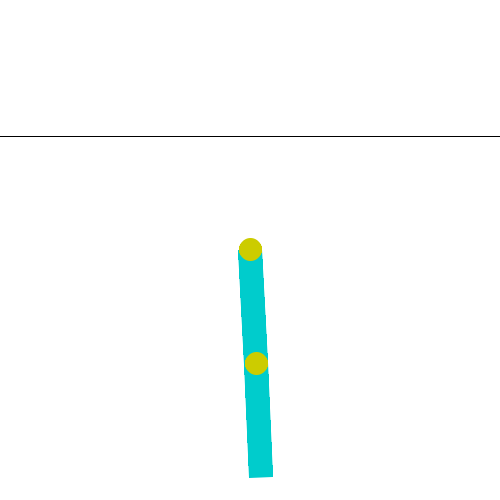

**Висновок до завдання 1:** випадковий агент майже ніколи не досягає мети - епізод обривається через 500 кроків з винагородою близько −500. Отже, потрібно навчити агента обирати дії розумно. Для цього далі реалізуємо алгоритм Q-learning.

## Завдання 3. Реалізація алгоритму Q-learning

Роботу поділено на частини:
- **3.1** - дискретизація простору станів;
- **3.2** - Q-таблиця, ε-greedy та цикл навчання;
- **3.3** - аналіз результатів навчання.

### 3.1 Дискретизація простору станів

Q-таблиця - це звичайна таблиця: кожен **рядок** - це стан, кожен **стовпець** - дія. Але стан Acrobot складається з дробових чисел, тому можливих станів нескінченно багато, і таблицю такого розміру створити неможливо.

Тому кожне число ми розбиваємо на кілька **проміжків («кошиків»)** і замінюємо його номером проміжку. Близькі стани потрапляють в один кошик, і агент вважає їх однаковими.

**Що ми дискретизуємо.** Замість 6 чисел `cos θ1, sin θ1, cos θ2, sin θ2, ω1, ω2` беремо 4:
- `θ1 = arctan2(sin θ1, cos θ1)` - кут верхнього стрижня (від −π до π);
- `θ2 = arctan2(sin θ2, cos θ2)` - кут нижнього стрижня відносно верхнього (від −π до π);
- `ω1`, `ω2` - кутові швидкості.

Пара (cos, sin) описує один кут, тож перетворення на сам кут не втрачає інформації. Зате Q-таблиця стає значно меншою: 10⁴ станів замість 10⁶ при 10 кошиках на кожне число.

**Межі швидкостей.** Теоретичні межі - ±12.57 та ±28.27, але насправді швидкості рідко бувають такими великими. Якщо розбити весь теоретичний діапазон, більшість кошиків ніколи не використовуватимуться. Тому беремо робочі межі ±6 та ±12; все, що виходить за них, потрапляє в крайній кошик.

In [7]:
# Простий приклад: як працює розбиття на кошики
# Ділимо відрізок [-π, π] на 5 рівних кошиків
edges_example = np.linspace(-np.pi, np.pi, 5 + 1)[1:-1] # внутрішні межі між кошиками
print("Межі кошиків:", np.round(edges_example, 2))

for angle in [-3.0, -1.5, 0.0, 1.0, 2.9]:
    print(f"кут {angle:5.1f}  ->  кошик №{np.digitize(angle, edges_example)}")

Межі кошиків: [-1.88 -0.63  0.63  1.88]
кут  -3.0  ->  кошик №0
кут  -1.5  ->  кошик №1
кут   0.0  ->  кошик №2
кут   1.0  ->  кошик №3
кут   2.9  ->  кошик №4


In [8]:
# Параметри дискретизації
N_BINS = [10, 10, 10, 10] # кількість кошиків для θ1, θ2, ω1, ω2
LOW  = np.array([-np.pi, -np.pi, -6.0, -12.0]) # нижні межі
HIGH = np.array([ np.pi,  np.pi,  6.0,  12.0]) # верхні межі

# Для кожної з 4 величин рахуємо внутрішні межі між кошиками
BIN_EDGES = [np.linspace(LOW[i], HIGH[i], N_BINS[i] + 1)[1:-1] for i in range(4)]


def obs_to_features(obs):
    """Перетворює 6 чисел стану на 4: два кути і дві швидкості."""
    cos1, sin1, cos2, sin2, vel1, vel2 = obs
    theta1 = np.arctan2(sin1, cos1)
    theta2 = np.arctan2(sin2, cos2)
    return np.array([theta1, theta2, vel1, vel2])


def discretize(obs):
    """Перетворює неперервний стан на кортеж з 4 номерів кошиків."""
    features = obs_to_features(obs)
    return tuple(int(np.digitize(features[i], BIN_EDGES[i])) for i in range(4))

In [9]:
# Перевірка: дивимось, як дискретизуються перші 5 станів епізоду
env = gym.make("Acrobot-v1")
obs, info = env.reset(seed=42)
for step in range(5):
    print("стан:", np.round(obs, 3))
    print("   кути і швидкості:", np.round(obs_to_features(obs), 3))
    print("   номер кошика (дискретний стан):", discretize(obs))
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
env.close()

n_states = np.prod(N_BINS)
print("\nКількість дискретних станів:", n_states)
print("Розмір Q-таблиці:", N_BINS + [3], "=", n_states * 3, "чисел")

стан: [ 0.998  0.055  1.    -0.012  0.072  0.039]
   кути і швидкості: [ 0.055 -0.012  0.072  0.039]
   номер кошика (дискретний стан): (5, 4, 5, 5)
стан: [ 0.999  0.048  0.999  0.036 -0.132  0.437]
   кути і швидкості: [ 0.048  0.036 -0.132  0.437]
   номер кошика (дискретний стан): (5, 5, 4, 5)
стан: [ 0.999  0.032  0.996  0.086 -0.03   0.052]
   кути і швидкості: [ 0.032  0.086 -0.03   0.052]
   номер кошика (дискретний стан): (5, 5, 4, 5)
стан: [ 1.     0.01   0.992  0.124 -0.177  0.319]
   кути і швидкості: [ 0.01   0.124 -0.177  0.319]
   номер кошика (дискретний стан): (5, 5, 4, 5)
стан: [ 1.    -0.022  0.985  0.172 -0.14   0.154]
   кути і швидкості: [-0.022  0.173 -0.14   0.154]
   номер кошика (дискретний стан): (4, 5, 4, 5)

Кількість дискретних станів: 10000
Розмір Q-таблиці: [10, 10, 10, 10, 3] = 30000 чисел


**Висновок до 3.1:** ми перетворили нескінченну кількість станів на 10 000 дискретних (10 кошиків × 4 величини). Кожен стан тепер - це кортеж з 4 цілих чисел, наприклад `(5, 4, 5, 5)`, який можна використати як адресу в Q-таблиці розміром 10×10×10×10×3.

### 3.2 Q-таблиця, ε-greedy та цикл навчання

**Гіперпараметри:**
- `N_EPISODES = 6000` - кількість епізодів навчання;
- `ALPHA = 0.2` - швидкість навчання α: нове значення Q на 20% складається з нової інформації і на 80% зі старого значення;
- `GAMMA = 0.99` - коефіцієнт знецінення γ: близький до 1, бо в Acrobot важливо планувати наперед (розгойдування займає багато кроків);
- `ε` спадає лінійно від 1.0 до 0.01 протягом перших 30% епізодів: спочатку агент переважно досліджує, потім переважно використовує вивчене.

In [10]:
# Гіперпараметри навчання
N_EPISODES = 6000 # скільки епізодів (партій гри) тренуємо агента
ALPHA = 0.2 # learning rate: наскільки сильно оновлюємо Q-значення
GAMMA = 0.99 # discount factor: наскільки цінуємо майбутні нагороди
EPSILON_START = 1.0 # на початку агент діє повністю випадково
EPSILON_MIN = 0.01 # мінімальна ймовірність випадкової дії
EPSILON_DECAY = (EPSILON_START - EPSILON_MIN) / (N_EPISODES * 0.3)  # ε спадає до мінімуму за перші 30% епізодів

N_ACTIONS = 3

**Q-таблиця** - багатовимірний масив розміром 10×10×10×10×3. Перші 4 індекси - це дискретний стан (номери кошиків), останній - дія. Спочатку всі значення нульові: агент ще нічого не знає.

In [11]:
# Створюємо Q-таблицю, заповнену нулями: 10 x 10 x 10 x 10 станів x 3 дії
q_table = np.zeros(N_BINS + [N_ACTIONS])
print("Форма Q-таблиці:", q_table.shape)

# Приклад: Q-значення для стану (5, 4, 5, 5) - поки що всі нулі
print("Q-значення для стану (5, 4, 5, 5):", q_table[(5, 4, 5, 5)])

Форма Q-таблиці: (10, 10, 10, 10, 3)
Q-значення для стану (5, 4, 5, 5): [0. 0. 0.]


**ε-greedy стратегія:** з ймовірністю ε агент робить випадкову дію (досліджує середовище), а з ймовірністю 1−ε - дію з найбільшим Q-значенням у поточному стані (використовує вже вивчене).

In [12]:
rng = np.random.default_rng(seed=0) # генератор випадкових чисел (seed - для відтворюваності)

def choose_action(state, epsilon):
    """ε-greedy: з ймовірністю ε - випадкова дія, інакше - найкраща за Q-таблицею."""
    if rng.random() < epsilon:
        return int(rng.integers(N_ACTIONS)) # дослідження (exploration)
    return int(np.argmax(q_table[state])) # використання знань (exploitation)

**Цикл навчання.** У кожному епізоді агент грає від початку до кінця. На кожному кроці він:
1. вибирає дію за ε-greedy;
2. робить крок і отримує новий стан та винагороду;
3. оновлює Q-значення за формулою  
   Q(s,a) = (1 − α)·Q(s,a) + α·(r + γ·max Q(s', a'));  
   якщо мети досягнуто (`terminated`), майбутніх нагород немає, тому ціль - просто r;
4. переходить у новий стан.

Після кожного епізоду ε зменшується. Навчання триває приблизно 2 хвилини.

In [13]:
import time

env = gym.make("Acrobot-v1")
epsilon = EPSILON_START
episode_rewards = [] # винагорода за кожен епізод
epsilons = [] # значення ε у кожному епізоді
start_time = time.time()

for episode in range(N_EPISODES):
    obs, info = env.reset(seed=episode)
    state = discretize(obs)
    total_reward = 0
    done = False

    while not done:
        # 1. Вибираємо дію за ε-greedy
        action = choose_action(state, epsilon)

        # 2. Робимо крок у середовищі
        obs, reward, terminated, truncated, info = env.step(action)
        next_state = discretize(obs)

        # 3. Оновлюємо Q-таблицю за формулою Q-learning
        if terminated:
            target = reward # мети досягнуто - майбутнього немає
        else:
            target = reward + GAMMA * np.max(q_table[next_state]) # r + γ·max Q(s', a')
        q_table[state + (action,)] = (1 - ALPHA) * q_table[state + (action,)] + ALPHA * target

        # 4. Переходимо в новий стан
        state = next_state
        total_reward += reward
        done = terminated or truncated

    # Після епізоду зменшуємо ε
    epsilon = max(EPSILON_MIN, epsilon - EPSILON_DECAY)
    episode_rewards.append(total_reward)
    epsilons.append(epsilon)

    # Кожні 500 епізодів друкуємо прогрес
    if (episode + 1) % 500 == 0:
        avg = np.mean(episode_rewards[-500:])
        print(f"Епізод {episode + 1:5d} | середня винагорода за останні 500: {avg:7.1f} | ε = {epsilon:.3f} | час: {time.time() - start_time:.0f} с")

env.close()
print("\nНавчання завершено!")

Епізод   500 | середня винагорода за останні 500:  -489.0 | ε = 0.725 | час: 13 с
Епізод  1000 | середня винагорода за останні 500:  -394.8 | ε = 0.450 | час: 24 с
Епізод  1500 | середня винагорода за останні 500:  -282.9 | ε = 0.175 | час: 32 с
Епізод  2000 | середня винагорода за останні 500:  -207.9 | ε = 0.010 | час: 38 с
Епізод  2500 | середня винагорода за останні 500:  -237.3 | ε = 0.010 | час: 44 с
Епізод  3000 | середня винагорода за останні 500:  -236.2 | ε = 0.010 | час: 51 с
Епізод  3500 | середня винагорода за останні 500:  -196.6 | ε = 0.010 | час: 56 с
Епізод  4000 | середня винагорода за останні 500:  -201.8 | ε = 0.010 | час: 62 с
Епізод  4500 | середня винагорода за останні 500:  -180.4 | ε = 0.010 | час: 67 с
Епізод  5000 | середня винагорода за останні 500:  -182.9 | ε = 0.010 | час: 72 с
Епізод  5500 | середня винагорода за останні 500:  -177.0 | ε = 0.010 | час: 77 с
Епізод  6000 | середня винагорода за останні 500:  -182.3 | ε = 0.010 | час: 82 с

Навчання заверш

**Висновок до 3.2:** під час навчання середня винагорода зростає з приблизно −490 (агент діє випадково) до приблизно −180, тобто агент навчився досягати мети значно швидше, ніж за 500 кроків.

### 3.3 Аналіз результатів навчання

**Графік навчання.** Світла лінія - винагорода в кожному окремому епізоді (вона дуже «шумна»). Темна лінія - ковзне середнє за 100 епізодів, на ній добре видно загальну тенденцію. Нижній графік показує, як зменшувалось ε.

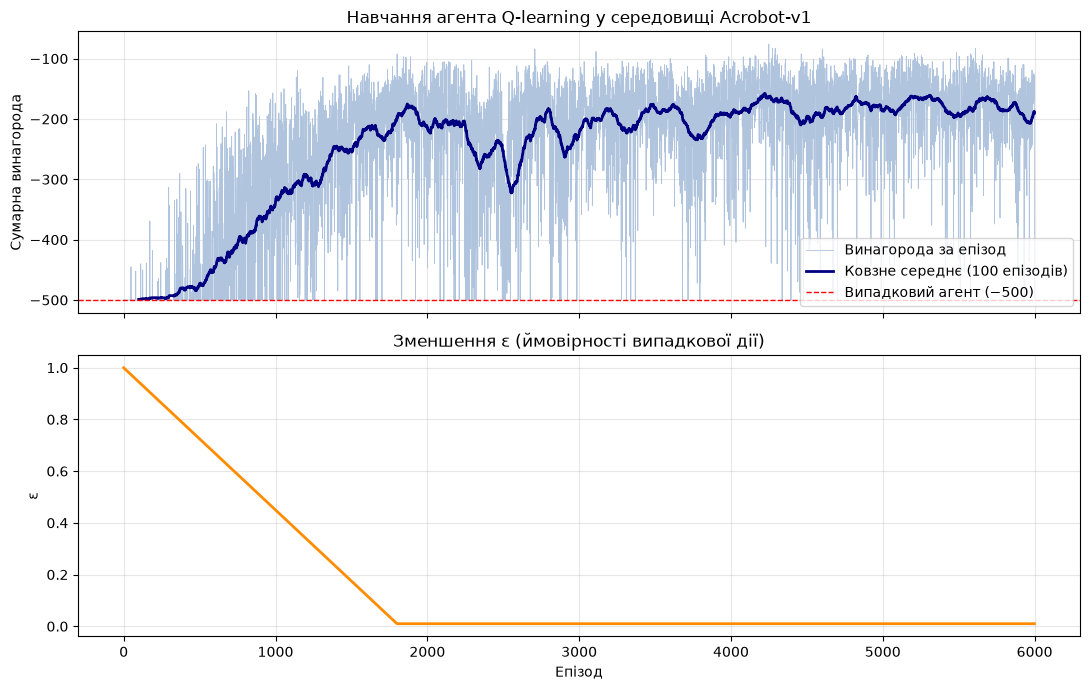

In [14]:
import matplotlib.pyplot as plt

window = 100
moving_avg = np.convolve(episode_rewards, np.ones(window) / window, mode="valid")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(episode_rewards, color="lightsteelblue", linewidth=0.6, label="Винагорода за епізод")
ax1.plot(range(window - 1, len(episode_rewards)), moving_avg, color="navy", linewidth=2,
         label=f"Ковзне середнє ({window} епізодів)")
ax1.axhline(-500, color="red", linestyle="--", linewidth=1, label="Випадковий агент (−500)")
ax1.set_ylabel("Сумарна винагорода")
ax1.set_title("Навчання агента Q-learning у середовищі Acrobot-v1")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

ax2.plot(epsilons, color="darkorange", linewidth=2)
ax2.set_xlabel("Епізод")
ax2.set_ylabel("ε")
ax2.set_title("Зменшення ε (ймовірності випадкової дії)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curve.png", dpi=120)
plt.show()

**Тестування.** Тепер перевіряємо навченого агента **без випадкових дій** (ε = 0): у кожному стані він бере дію з найбільшим Q-значенням. Для порівняння на тих самих 100 епізодах (з тими самими початковими станами) грає випадковий агент.

In [15]:
def play_episode(env, policy, seed):
    """Грає один епізод. policy - функція, що за станом obs повертає дію."""
    obs, info = env.reset(seed=seed)
    total_reward = 0
    done = False
    while not done:
        obs, reward, terminated, truncated, info = env.step(policy(obs))
        total_reward += reward
        done = terminated or truncated
    return total_reward

def trained_policy(obs):
    return int(np.argmax(q_table[discretize(obs)])) # тільки найкраща дія, без випадковості (ε = 0)

def random_policy(obs):
    return env.action_space.sample()

N_TEST = 100
env = gym.make("Acrobot-v1")
trained_rewards = [play_episode(env, trained_policy, seed=10000 + i) for i in range(N_TEST)]
random_rewards_test = [play_episode(env, random_policy, seed=10000 + i) for i in range(N_TEST)]
env.close()

for name, rewards in [("Навчений агент", trained_rewards), ("Випадковий агент", random_rewards_test)]:
    rewards = np.array(rewards)
    print(f"{name}:")
    print(f"   середня винагорода: {rewards.mean():.1f}")
    print(f"   найкраща / найгірша: {rewards.max():.0f} / {rewards.min():.0f}")
    print(f"   успішних епізодів (досягнуто мети): {(rewards > -500).sum()} з {N_TEST}")

Навчений агент:
   середня винагорода: -167.5
   найкраща / найгірша: -97 / -488
   успішних епізодів (досягнуто мети): 100 з 100
Випадковий агент:
   середня винагорода: -498.8
   найкраща / найгірша: -439 / -500
   успішних епізодів (досягнуто мети): 3 з 100


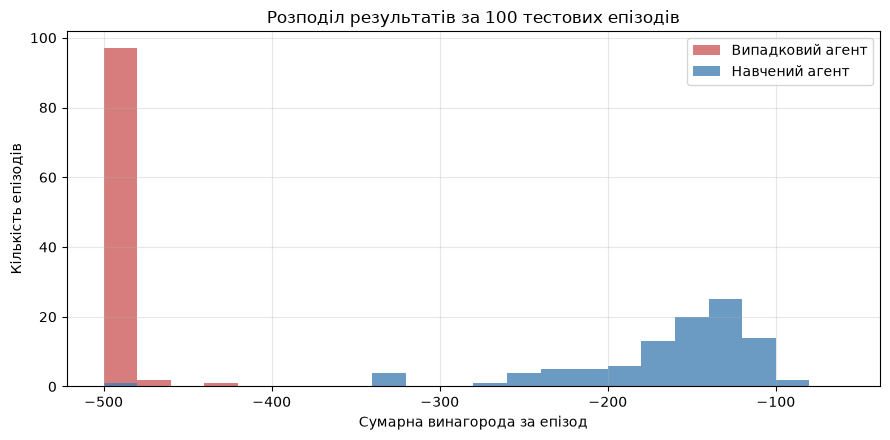

In [16]:
plt.figure(figsize=(9, 4.5))
bins = np.arange(-500, -50, 20)
plt.hist(random_rewards_test, bins=bins, color="indianred", alpha=0.8, label="Випадковий агент")
plt.hist(trained_rewards, bins=bins, color="steelblue", alpha=0.8, label="Навчений агент")
plt.xlabel("Сумарна винагорода за епізод")
plt.ylabel("Кількість епізодів")
plt.title(f"Розподіл результатів за {N_TEST} тестових епізодів")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("test_comparison.png", dpi=120)
plt.show()

**Візуалізація навченого агента.**

Мети досягнуто за 114 кроків (terminated = True)


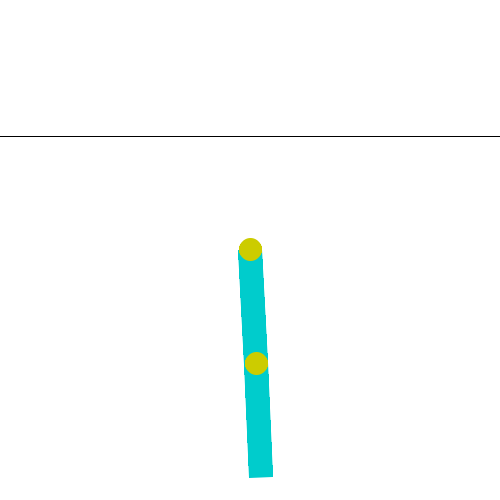

In [17]:
# GIF: навчений агент грає один епізод
from PIL import Image as PILImage
from IPython.display import Image, display

env = gym.make("Acrobot-v1", render_mode="rgb_array")
obs, info = env.reset(seed=42)
frames = [PILImage.fromarray(env.render())]
done = False
steps = 0
while not done:
    obs, reward, terminated, truncated, info = env.step(trained_policy(obs))
    frames.append(PILImage.fromarray(env.render()))
    steps += 1
    done = terminated or truncated
env.close()

# Кілька разів повторюємо останній кадр, щоб було видно момент досягнення мети
frames += [frames[-1]] * 25
frames[0].save("acrobot_trained.gif", save_all=True, append_images=frames[1:], duration=40, loop=0)
print(f"Мети досягнуто за {steps} кроків (terminated = {terminated})")
display(Image(filename="acrobot_trained.gif"))

**Висновок до 3.3:** навчений агент досягає мети в усіх (або майже всіх) тестових епізодах із середньою винагородою близько −180, тобто приблизно за 180 кроків. Випадковий агент на тих самих епізодах майже ніколи не досягає мети (≈ −500). Отже, алгоритм Q-learning з дискретизацією простору станів успішно навчив агента розв'язувати задачу Acrobot.

## Завдання 4. Збереження результатів навчання

Щоб показати роботу агента на захисті, не потрібно навчати його знову (це займає кілька хвилин). Достатньо зберегти **Q-таблицю** у файл, а потім завантажити її і запустити гру.

Разом із таблицею зберігаємо **параметри дискретизації** (`N_BINS`, `LOW`, `HIGH`): щоб таблиця працювала, стан треба розбивати на кошики точно так само, як під час навчання.

Формат `.npz` - це стандартний формат numpy, який зберігає кілька масивів в одному файлі.

In [18]:
# Зберігаємо все, що потрібно, щоб відтворити агента без повторного навчання
MODEL_FILE = "acrobot_q_learning.npz"
np.savez(
    MODEL_FILE,
    q_table=q_table, # навчена Q-таблиця
    n_bins=np.array(N_BINS), # параметри дискретизації
    low=LOW, # без них не вийде правильно
    high=HIGH, # перетворити стан на номери кошиків
    episode_rewards=np.array(episode_rewards), # історія навчання (для графіків)
)

import os
print(f"Модель збережено у файл {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1024:.0f} КБ)")

Модель збережено у файл acrobot_q_learning.npz (283 КБ)


## Висновки

У цій лабораторній роботі я реалізував алгоритм **Q-learning** для середовища **Acrobot-v1** з бібліотеки Gymnasium.

Що було зроблено:
- ознайомився з середовищем: агент має 3 дії, а стан описується 6 неперервними числами;
- перевірив випадкового агента: він майже ніколи не досягає мети і отримує близько -500;
- щоб використати Q-таблицю, **дискретизував** стан: перетворив його на 2 кути і 2 швидкості та розбив кожну величину на 10 проміжків. Вийшла Q-таблиця розміром 10 x 10 x 10 x 10 x 3;
- навчив агента за 6000 епізодів (α = 0.2, γ = 0.99, ε спадає від 1 до 0.01), навчання зайняло близько 1.5 хвилини;
- зберіг навчену модель у файл `acrobot_q_learning.npz` і написав скрипт `play_acrobot.py` для демонстрації.

Результати на 100 тестових епізодах:

| Агент | Середня винагорода | Успішних епізодів |
|---|---|---|
| Випадковий | -498.8 | 3 з 100 |
| Навчений (Q-learning) | -167.5 | 100 з 100 |

Навчений агент досягає мети в кожному епізоді, в середньому приблизно за 168 кроків (найкраще - за 97 кроків). Отже, Q-learning з дискретизацією станів успішно розв'язує задачу Acrobot. Головний недолік підходу - дискретизація об'єднує різні стани в один, через що навчання має коливання і результат не ідеальний.

## Відповіді на контрольні питання

**1. Що таке навчання з підкріпленням?**  
Це вид машинного навчання, де агент вчиться методом спроб і помилок. Він робить дії в середовищі, отримує за них нагороду і поступово вчиться діяти так, щоб загальна нагорода була якомога більшою. Правильних відповідей наперед йому ніхто не дає.

**2. Які сфери Q-learning?**  
Ігри, робототехніка (керування рухом), навігація і автопілоти, керування ресурсами (енергія, світлофори), рекомендаційні системи, торгівля.

**3. Який процес називається Марківським процесом прийняття рішень?**  
Це математична модель задачі, де є: стани S, дії A, ймовірності переходу між станами P, нагорода R і коефіцієнт γ. Головна властивість (марківська): наступний стан залежить тільки від поточного стану і дії, а не від усієї історії.

**4. У чому відмінність між МППР та Q-learning?**  
МППР - це **опис задачі** (модель світу). Q-learning - це **алгоритм розв'язання** такої задачі. Q-learning не потребує знати ймовірності переходів і нагороди заздалегідь, він дізнається їх з досвіду.

**5. Поняття нагороди. Миттєва і відкладена нагороди.**  
Нагорода - це число, яке середовище дає агенту після дії і яке показує, наскільки дія була доброю.  
**Миттєва** нагорода - отримана одразу за цей крок.  
**Відкладена** - коли користь від дії видно лише через багато кроків. Наприклад, в Acrobot розгойдування окупається тільки тоді, коли кінчик дістане до лінії. Q-learning враховує відкладені нагороди через доданок γ·max Q(s', a').

**6. Яких умов повинен дотримуватись learning rate α?**  
0 < α ≤ 1. Щоб алгоритм точно зійшовся, α треба поступово зменшувати (сума всіх α нескінченна, а сума їх квадратів скінченна, наприклад α = 1/t), і кожна пара стан-дія має відвідуватись багато разів. На практиці беруть невелике стале значення (0.1-0.2): занадто велике α - навчання нестабільне, занадто мале - дуже повільне.

**7. Поясніть суть параметру γ.**  
γ (від 0 до 1) показує, наскільки агент цінує майбутні нагороди. γ = 0 - агент дивиться тільки на нагороду зараз, γ близько до 1 - агент планує далеко наперед. У нас γ = 0.99, бо для розгойдування треба думати на багато кроків уперед.

**8. Що таке ε-greedy стратегія? Чому її варто використовувати?**  
З ймовірністю ε агент робить випадкову дію, а в інших випадках - найкращу за Q-таблицею. Це потрібно, щоб агент не тільки використовував те, що вже знає, а й пробував нове. Без цього він може застрягнути на першій знайденій, але не найкращій стратегії. Зазвичай ε зменшують з часом.

**9. Неперервний та дискретний простори дій та станів.**  
**Дискретний** простір має скінченну кількість значень, наприклад дії в Acrobot: 0, 1, 2.  
**Неперервний** простір - це будь-які числа з проміжку, їх нескінченно багато, наприклад кути і швидкості в Acrobot.

**10. Для чого використовувати дискретизацію просторів?**  
Q-таблиця може мати лише скінченну кількість рядків. Тому неперервні значення розбивають на проміжки і замінюють номером проміжку. Так нескінченна кількість станів стає скінченною, і Q-learning можна застосувати. Мінус - втрачається точність, бо різні стани потрапляють в один проміжок.